# Project 8: Gradient Descent Implementation
**Deep Learning Assignment**

**Objective:** Implement a simple Gradient Descent algorithm from scratch to understand how a model updates its parameters and reduces prediction error during training.

| Task | Description |
|---|---|
| Task 1 | Use a simple classification example to initialize model parameters |
| Task 2 | Write Python code to implement Gradient Descent and update the parameters |
| Task 3 | Display and analyze how the loss decreases over multiple iterations |

**Model:** Logistic regression (a single neuron with sigmoid activation), $\hat{y} = \sigma(wx + b)$

**Loss:** Binary Cross-Entropy, $L = -\frac{1}{m}\sum [\,y\log\hat{y} + (1-y)\log(1-\hat{y})\,]$

**Gradients:** $\frac{\partial L}{\partial w} = \frac{1}{m}\sum(\hat{y}-y)x$, $\quad \frac{\partial L}{\partial b} = \frac{1}{m}\sum(\hat{y}-y)$

**Update rule:** $\text{parameter} = \text{parameter} - \text{learning rate} \times \text{gradient}$

## Task 1: Dataset and Parameter Initialization
A simple dataset of 16 students: input `x` = hours studied, label `y` = 1 (pass) or 0 (fail). The data slightly overlaps (a student who studied 6 hours failed, while one who studied 5 hours passed), as real data usually does.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

hours = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10,
                  2.5, 3.5, 4.5, 5.5, 6.5, 7.5])
passed = np.array([0, 0, 0, 0, 1, 0, 1, 1, 1, 1,
                   0, 0, 0, 1, 1, 1])

X, y = hours, passed
m = len(X)                      # number of training examples

w = 0.0                         # weight (slope) - initialized to 0
b = 0.0                         # bias (intercept) - initialized to 0
learning_rate = 0.1
iterations = 500

print("TASK 1: Initialization")
print(f"Number of samples : {m}")
print(f"Initial weight w  : {w}")
print(f"Initial bias b    : {b}")
print(f"Learning rate     : {learning_rate}")
print(f"Iterations        : {iterations}")

TASK 1: Initialization
Number of samples : 16
Initial weight w  : 0.0
Initial bias b    : 0.0
Learning rate     : 0.1
Iterations        : 500


With $w = 0$ and $b = 0$, the model predicts a probability of 0.5 for every student, so the starting loss is $\ln 2 \approx 0.6931$.

## Task 2: Gradient Descent Implementation
Each iteration does a forward pass, computes the loss, computes the gradients `dw` and `db`, and then updates `w` and `b`.

In [2]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def compute_loss(y_true, y_pred):
    """Binary Cross-Entropy loss."""
    eps = 1e-12
    y_pred = np.clip(y_pred, eps, 1 - eps)
    return -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))

def gradient_descent(X, y, w, b, lr, n_iter):
    m = len(X)
    loss_history, w_history, b_history = [], [], []
    for i in range(n_iter):
        # Forward pass
        y_pred = sigmoid(w * X + b)
        # Loss
        loss = compute_loss(y, y_pred)
        # Gradients of the loss with respect to w and b
        dw = np.dot(y_pred - y, X) / m
        db = np.mean(y_pred - y)
        # Parameter update: parameter = parameter - lr * gradient
        w = w - lr * dw
        b = b - lr * db
        loss_history.append(loss)
        w_history.append(w)
        b_history.append(b)
    return w, b, loss_history, w_history, b_history

In [3]:
w_final, b_final, loss_hist, w_hist, b_hist = gradient_descent(
    X, y, w, b, learning_rate, iterations)

print("Training finished.")
print(f"Final w = {w_final:.4f}, final b = {b_final:.4f}")

Training finished.
Final w = 0.7522, final b = -3.6992


## Task 3: Display and Analyze the Loss Reduction

### 3.1 Parameter updates and loss at selected iterations
The table shows the loss at each iteration with the values of `w` and `b` after that iteration's update.

In [4]:
print(f"{'Iter':>5} {'Loss':>10} {'w':>10} {'b':>10}")
for i in list(range(0, 10)) + [24, 49, 99, 199, 299, 399, 499]:
    print(f"{i+1:>5} {loss_hist[i]:>10.4f} {w_hist[i]:>10.4f} {b_hist[i]:>10.4f}")

preds = (sigmoid(w_final * X + b_final) >= 0.5).astype(int)
accuracy = np.mean(preds == y) * 100
print(f"\nInitial loss : {loss_hist[0]:.4f}")
print(f"Final loss   : {loss_hist[-1]:.4f}")
print(f"Loss reduced by {(1 - loss_hist[-1] / loss_hist[0]) * 100:.2f}%")
print(f"Final w = {w_final:.4f}, b = {b_final:.4f}")
print(f"Training accuracy = {accuracy:.2f}%")

 Iter       Loss          w          b
    1     0.6931     0.1000     0.0000
    2     0.6353     0.1175    -0.0128
    3     0.6315     0.1237    -0.0273
    4     0.6291     0.1271    -0.0422
    5     0.6267     0.1297    -0.0572
    6     0.6244     0.1322    -0.0721
    7     0.6222     0.1346    -0.0870
    8     0.6199     0.1370    -0.1018
    9     0.6176     0.1394    -0.1166
   10     0.6154     0.1417    -0.1313
   25     0.5841     0.1762    -0.3446
   50     0.5397     0.2298    -0.6720
  100     0.4735     0.3240    -1.2373
  200     0.3943     0.4727    -2.1084
  300     0.3503     0.5860    -2.7590
  400     0.3227     0.6768    -3.2742
  500     0.3040     0.7522    -3.6992

Initial loss : 0.6931
Final loss   : 0.3040
Loss reduced by 56.14%
Final w = 0.7522, b = -3.6992
Training accuracy = 93.75%


### 3.2 Loss vs. iterations

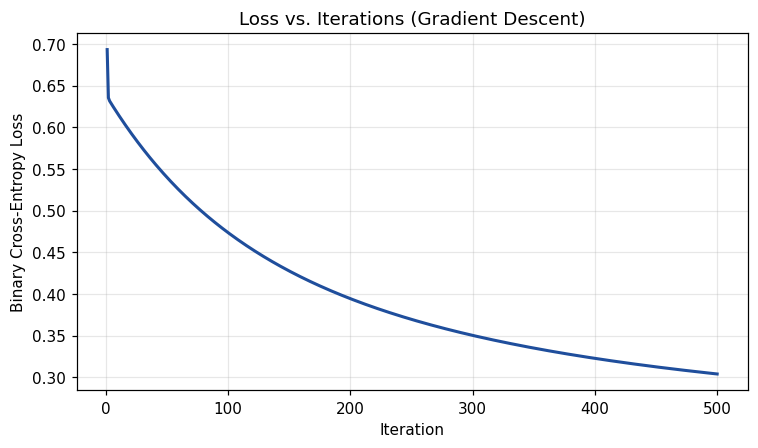

In [5]:
plt.figure(figsize=(7, 4.2))
plt.plot(range(1, iterations + 1), loss_hist, color="#1f4e9c", linewidth=2)
plt.title("Loss vs. Iterations (Gradient Descent)")
plt.xlabel("Iteration"); plt.ylabel("Binary Cross-Entropy Loss")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

### 3.3 Parameter updates over iterations

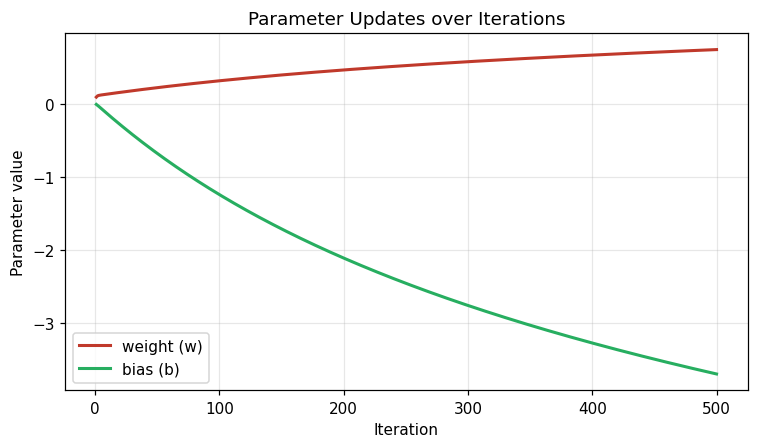

In [6]:
plt.figure(figsize=(7, 4.2))
plt.plot(range(1, iterations + 1), w_hist, label="weight (w)", color="#c0392b", linewidth=2)
plt.plot(range(1, iterations + 1), b_hist, label="bias (b)", color="#27ae60", linewidth=2)
plt.title("Parameter Updates over Iterations")
plt.xlabel("Iteration"); plt.ylabel("Parameter value")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

### 3.4 Model fit before and after training

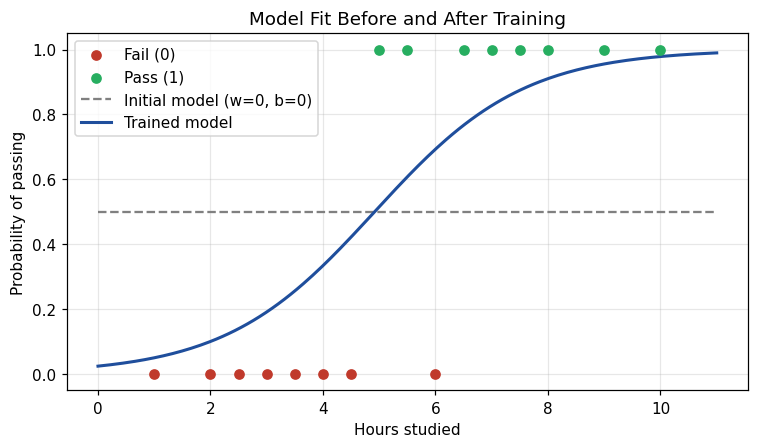

In [7]:
xs = np.linspace(0, 11, 200)
plt.figure(figsize=(7, 4.2))
plt.scatter(X[y == 0], y[y == 0], color="#c0392b", label="Fail (0)", zorder=3)
plt.scatter(X[y == 1], y[y == 1], color="#27ae60", label="Pass (1)", zorder=3)
plt.plot(xs, sigmoid(0 * xs + 0), "--", color="gray", label="Initial model (w=0, b=0)")
plt.plot(xs, sigmoid(w_final * xs + b_final), color="#1f4e9c", linewidth=2, label="Trained model")
plt.title("Model Fit Before and After Training")
plt.xlabel("Hours studied"); plt.ylabel("Probability of passing")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

### 3.5 Analysis

- **Loss decreases steadily.** The loss falls from 0.6931 at the first iteration to 0.3040 at iteration 500, a reduction of 56.14%. The curve never goes up, which shows the learning rate is suitable.
- **Fast at first, slower later.** The loss drops by about 0.22 in the first 100 iterations (0.6931 to 0.4735) but only by about 0.02 in the last 100 iterations (0.3227 to 0.3040). Near the minimum the gradients become small, so each update step is smaller.
- **Parameters move toward a good solution.** The weight `w` increases from 0 to 0.7522 and the bias `b` decreases from 0 to -3.6992. A positive weight means more study hours raise the probability of passing, and the negative bias shifts the decision boundary to the right.
- **Decision boundary.** The model predicts "pass" when $wx + b \ge 0$, that is when $x \ge 3.6992 / 0.7522 \approx 4.92$ hours, which matches the pattern in the data.
- **Accuracy.** The trained model classifies 15 of 16 students correctly (93.75%). The only error is the student who studied 6 hours but failed, which is the overlapping point in the data.
- **Not fully converged.** The loss is still decreasing slowly at iteration 500, so more iterations would reduce it further.

## Additional Experiment: Effect of the Learning Rate
The same training is repeated with three learning rates to see how the step size affects loss reduction.

Final loss after 500 iterations:
  lr = 0.01  -> final loss = 0.5385
  lr = 0.1   -> final loss = 0.3040
  lr = 0.3   -> final loss = 0.2453


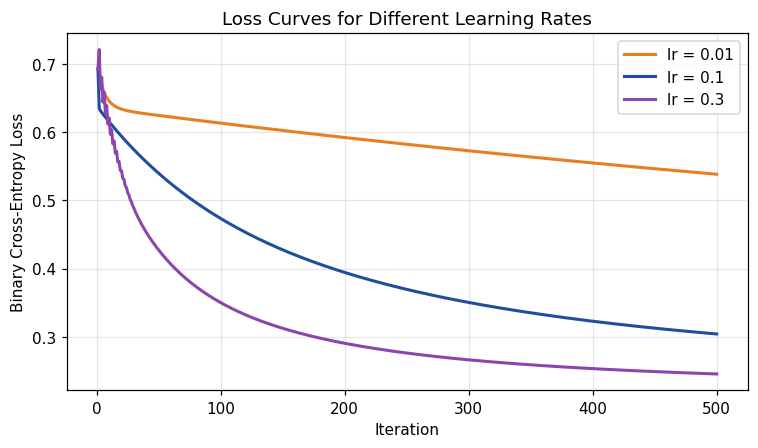

In [8]:
plt.figure(figsize=(7, 4.2))
print("Final loss after 500 iterations:")
for lr, color in [(0.01, "#e67e22"), (0.1, "#1f4e9c"), (0.3, "#8e44ad")]:
    _, _, lh, _, _ = gradient_descent(X, y, 0.0, 0.0, lr, iterations)
    plt.plot(range(1, iterations + 1), lh, label=f"lr = {lr}", color=color, linewidth=2)
    print(f"  lr = {lr:<5} -> final loss = {lh[-1]:.4f}")
plt.title("Loss Curves for Different Learning Rates")
plt.xlabel("Iteration"); plt.ylabel("Binary Cross-Entropy Loss")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

A very small learning rate (0.01) makes learning slow, and the loss is still high after 500 iterations. Larger learning rates reduce the loss faster. For this dataset 0.3 still works, but a learning rate that is too large can overshoot the minimum, making the loss oscillate or even increase. Choosing the learning rate is therefore an important part of training.

## Conclusion
Gradient Descent was implemented from scratch for a logistic regression classifier. Starting from $w = 0$ and $b = 0$, the algorithm repeatedly computed the gradients of the Binary Cross-Entropy loss and updated the parameters in the opposite direction. The loss fell from 0.6931 to 0.3040 over 500 iterations, the parameters settled at $w \approx 0.7522$ and $b \approx -3.6992$, and the model reached 93.75% training accuracy. The loss curve, parameter plot and model-fit plot clearly show how parameter updates reduce prediction error, which is the core idea behind training neural networks.